# Initialization and warm-up

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/random.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import supporting_reports as report
from gw.classification_report import show
import matplotlib.pyplot as plt
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

30 paired initializations · mean ± sample SD.

In [2]:
raw,table=report.toy(ROOT)
show(table)

,Initialization,Warm-up,Reduced seeds
Confidence bias ↓,0.40400 ± 0.06161,0.00948 ± 0.00369,30/30
Mean log response ↓,-1.1490 ± 1.0226,-6.0819 ± 1.5007,30/30


## Paired responses

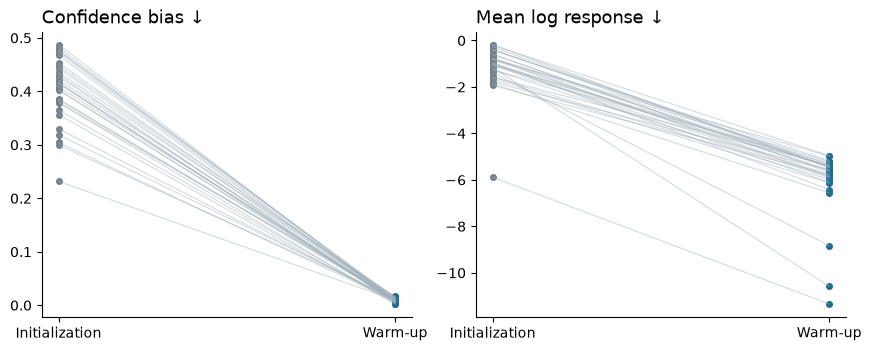

In [3]:
figure=report.toy_plot(raw,ROOT/'assets/figures/toy1.png')
display(figure)
plt.close(figure)

## Settings

2 → 10 → 10 → 2 MLP · uniform inputs in [−10, 10]² · 12,000 warm-up updates · balanced random hard labels · Adam, learning rate 0.0008.

Evaluation: 10,000 shared points and 32 unit directions; initialization seeds 100–129.

## Model evaluation

Measure bias and local response directly from the 60 saved model states.

In [4]:
measurements=report.toy_inference(ROOT)
show(measurements.groupby('Phase')[['Confidence bias','Mean log response']].agg(['mean','std']))
print(f'{len(measurements)} model states evaluated')

60 model states evaluated


## Training

Optional · one seed · balanced random hard labels. Set `RUN_TRAINING = True` to run.

In [5]:
import json
import pandas as pd
RUN_TRAINING = False
TRAIN_SEED = 100
TRAIN_STEPS = 12000

training_config = json.loads((ROOT / 'configs/toy1_training.json').read_text())
selection = pd.DataFrame([{'Seed': TRAIN_SEED, 'Updates': TRAIN_STEPS,
                          'Batch size': training_config['warmup']['batch_size'],
                          'Learning rate': training_config['warmup']['learning_rate']}])
display(selection.style.hide(axis='index'))

if RUN_TRAINING:
    from gw.toy_training import train
    training_directory = train(ROOT, TRAIN_SEED, steps=TRAIN_STEPS)
    metrics = pd.read_csv(training_directory / 'metrics.csv')
    view = metrics[['step', 'confidence_bias', 'mean_log_response']].rename(columns={
        'step': 'Updates', 'confidence_bias': 'Confidence bias',
        'mean_log_response': 'Mean log response'})
    display(view.style.hide(axis='index').format({'Confidence bias': '{:.5f}',
                                                'Mean log response': '{:.4f}'}))
    print(training_directory)


Seed,Updates,Batch size,Learning rate
100,12000,2048,0.000800
